In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/raw")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

visits = pd.read_csv(DATA / "air_visit_data.csv", parse_dates=["visit_date"])

count    252108.0
mean         21.0
std          16.8
min           1.0
50%          17.0
90%          43.0
99%          73.0
99.9%       115.0
max         877.0
Name: visitors, dtype: float64
skew raw: 3.31
skew log1p: -0.45


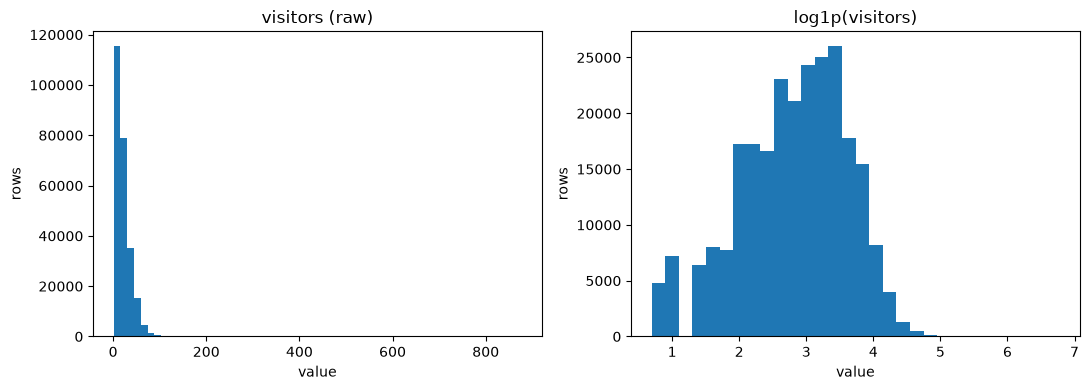

In [10]:
v = visits["visitors"]
print(v.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1))
print("skew raw:", round(v.skew(), 2))
print("skew log1p:", round(np.log1p(v).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(v, bins=60)
axes[0].set_title("visitors (raw)")
axes[1].hist(np.log1p(v), bins=30)
axes[1].set_title("log1p(visitors)")
for ax in axes:
    ax.set_xlabel("value")
    ax.set_ylabel("rows")
fig.tight_layout()
fig.savefig(FIG / "visitors_distribution.png", dpi=120)
plt.show()

In [12]:
print(visits.nlargest(10, "visitors"))

top = visits.loc[visits["visitors"].idxmax()]
s = visits[visits["air_store_id"] == top["air_store_id"]]
print(s["visitors"].describe().round(1))

# 3 days before and after the maximum
near = s[s["visit_date"].between(top["visit_date"] - pd.Timedelta(days=3),
                                 top["visit_date"] + pd.Timedelta(days=3))]
print(near)

q1, q3 = v.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("IQR upper fence:", upper, "| rows above:", (v > upper).sum())

lv = np.log1p(v)
lq1, lq3 = lv.quantile([0.25, 0.75])
lupper = lq3 + 1.5 * (lq3 - lq1)
print("log-scale rows above fence:", (lv > lupper).sum())

                air_store_id visit_date  visitors
85314   air_cfdeb326418194ff 2017-03-08       877
214825  air_8c3175aa5e4fc569 2017-04-18       777
72836   air_f2985de32bb792e0 2016-07-10       675
172123  air_eca5e0064dc9314a 2016-08-30       627
143894  air_43d577e0c9460e64 2016-01-24       514
167504  air_9828505fefc77d75 2016-11-19       409
147739  air_e42bdc3377d1eee7 2016-12-14       372
151243  air_cb083b4789a8d3a2 2016-01-14       369
141539  air_07bb665f9cdfbdfb 2016-08-07       351
200611  air_c6aa2efba0ffc8eb 2017-01-23       348
count    407.0
mean      17.1
std       43.8
min        1.0
25%        6.0
50%       15.0
75%       22.0
max      877.0
Name: visitors, dtype: float64
               air_store_id visit_date  visitors
85312  air_cfdeb326418194ff 2017-03-06         4
85313  air_cfdeb326418194ff 2017-03-07        11
85314  air_cfdeb326418194ff 2017-03-08       877
85315  air_cfdeb326418194ff 2017-03-09        17
85316  air_cfdeb326418194ff 2017-03-10        11
85317

In [15]:
top10 = visits.nlargest(10, "visitors").copy()
med = visits.groupby("air_store_id")["visitors"].median()
top10["store_median"] = top10["air_store_id"].map(med)
top10["ratio"] = (top10["visitors"] / top10["store_median"]).round(1)
print(top10)

# Are the 72 log-scale outliers spread out or concentrated in a few stores?
out72 = visits[lv > lupper]
print(out72["air_store_id"].value_counts().head(10))
print("stores involved:", out72["air_store_id"].nunique())

                air_store_id visit_date  visitors  store_median  ratio
85314   air_cfdeb326418194ff 2017-03-08       877          15.0   58.5
214825  air_8c3175aa5e4fc569 2017-04-18       777          29.0   26.8
72836   air_f2985de32bb792e0 2016-07-10       675          29.0   23.3
172123  air_eca5e0064dc9314a 2016-08-30       627          29.0   21.6
143894  air_43d577e0c9460e64 2016-01-24       514          31.0   16.6
167504  air_9828505fefc77d75 2016-11-19       409          15.0   27.3
147739  air_e42bdc3377d1eee7 2016-12-14       372          20.0   18.6
151243  air_cb083b4789a8d3a2 2016-01-14       369          26.0   14.2
141539  air_07bb665f9cdfbdfb 2016-08-07       351          28.0   12.5
200611  air_c6aa2efba0ffc8eb 2017-01-23       348          23.5   14.8
air_store_id
air_7514d90009613cd6    8
air_746211c0b532e8aa    4
air_df554c4527a1cfe6    3
air_eca5e0064dc9314a    3
air_1c0b150f9e696a5f    2
air_8f13ef0f5e8c64dd    2
air_b23d0f519291247d    2
air_d98380a4aeb0290b    

**Outlier policy (for now): keep all rows.**
Reason: it is not clear whether the extreme values are data errors or real events (for example a large group booking). The target will be log1p(visitors), which already limits their influence.
Revisit after: the first tuned model, during error analysis, to see whether the largest errors come from these rows.